Compare AUC-ROC scores of different models by manually computing true positive and false positive rates at various thresholds, plotting ROC curves without using built-in functions, and analyzing trade-offs in model performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 63
Testing records: 16


In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42
    )
}

probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

    print(name, "trained successfully")

Logistic Regression trained successfully
Random Forest trained successfully
XGBoost trained successfully


In [3]:
def calculate_roc_auc(y_true, y_scores):
    y_true = np.array(y_true)
    y_scores = np.array(y_scores)

    thresholds = np.sort(np.unique(y_scores))[::-1]
    thresholds = np.concatenate(([np.inf], thresholds, [-np.inf]))

    tpr_values = []
    fpr_values = []

    positives = np.sum(y_true == 1)
    negatives = np.sum(y_true == 0)

    for threshold in thresholds:
        predictions = (y_scores >= threshold).astype(int)

        tp = np.sum((y_true == 1) & (predictions == 1))
        fp = np.sum((y_true == 0) & (predictions == 1))

        tpr = tp / positives if positives else 0
        fpr = fp / negatives if negatives else 0

        tpr_values.append(tpr)
        fpr_values.append(fpr)

    points = sorted(zip(fpr_values, tpr_values))
    fpr_values = np.array([p[0] for p in points])
    tpr_values = np.array([p[1] for p in points])

    auc = np.sum(
        (fpr_values[1:] - fpr_values[:-1]) *
        (tpr_values[1:] + tpr_values[:-1]) / 2
    )

    return fpr_values, tpr_values, auc

In [4]:
roc_results = {}

for name, scores in probabilities.items():
    fpr, tpr, auc = calculate_roc_auc(y_test, scores)

    roc_results[name] = {
        "FPR": fpr,
        "TPR": tpr,
        "AUC": auc
    }

    print(name, "AUC:", round(auc, 4))

Logistic Regression AUC: 0.6042
Random Forest AUC: 0.6875
XGBoost AUC: 0.625


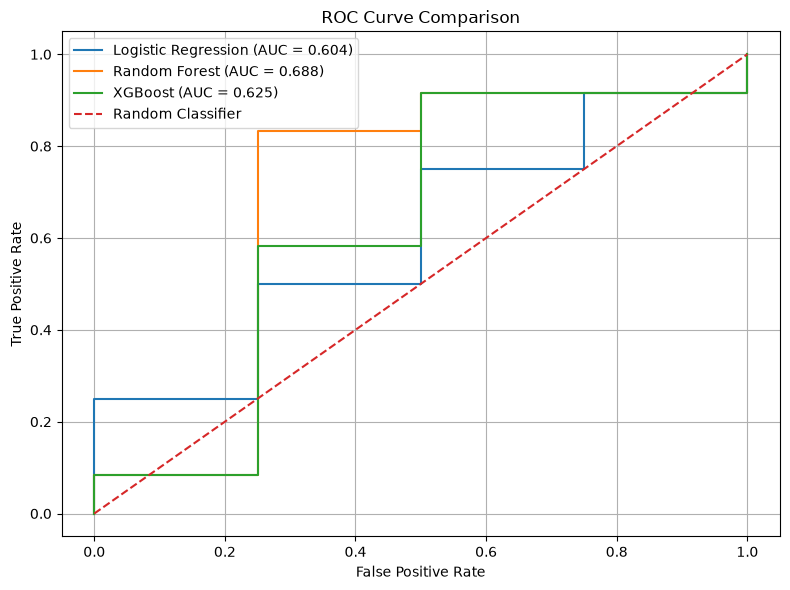

In [5]:
plt.figure(figsize=(8, 6))

for name, result in roc_results.items():
    plt.plot(
        result["FPR"],
        result["TPR"],
        label=f'{name} (AUC = {result["AUC"]:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
comparison = pd.DataFrame([
    {"Model": name, "AUC Score": result["AUC"]}
    for name, result in roc_results.items()
])

comparison = comparison.sort_values(
    "AUC Score", ascending=False
).reset_index(drop=True)

print("AUC Comparison")
print(comparison.round(4).to_string(index=False))

best_model = comparison.iloc[0]["Model"]
print("\nBest model based on AUC:", best_model)

for _, row in comparison.iterrows():
    auc = row["AUC Score"]

    if auc > 0.9:
        interpretation = "Excellent discrimination"
    elif auc > 0.8:
        interpretation = "Good discrimination"
    elif auc > 0.7:
        interpretation = "Fair discrimination"
    else:
        interpretation = "Limited discrimination"

    print(row["Model"] + ":", interpretation)

AUC Comparison
              Model  AUC Score
      Random Forest     0.6875
            XGBoost     0.6250
Logistic Regression     0.6042

Best model based on AUC: Random Forest
Random Forest: Limited discrimination
XGBoost: Limited discrimination
Logistic Regression: Limited discrimination
